**Цель работы:**

Изучение связи между признаками двумерного набора данных, визуализация данных.

# Лабораторная работа 2. Исследовательский анализ данных

### Описание предметной области

Вариант №14

Набор данных: clients.csv

Атрибуты:
- ID — уникальный идентификатор клиента;
- Year_Birth — год рождения клиента;
- Education — уровень образования клиента;
- Marital_Status — семейное положение клиента;
- Income — годовой доход семьи;
- Kidhome — количество детей;
- Dt_Customer — дата регистрации клиента в компании;
- NumDealsPurchases — количество покупок.

## 1. Загрузка и предварительная обработка данных

### 1.1 Подключение библиотек и загрузка набора данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('clients.csv', sep=';')

In [2]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Dt_Customer,NumDealsPurchases
0,5524,1957,Graduation,Single,58138.0,0.0,04.09.2012,3.0
1,2174,1954,Graduation,Single,46344.0,1.0,08.03.2014,2.0
2,4141,1965,Graduation,Together,71613.0,0.0,21.08.2013,1.0
3,6182,1984,Graduation,Together,26646.0,1.0,10.02.2014,2.0
4,5324,1981,PhD,Married,58293.0,1.0,19.01.2014,5.0


Набор данных успешно загружен. Одна строка соответствует одному клиенту магазина.

### 1.2 Оценка набора данных с помощью `info()`

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 796 entries, 0 to 795
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 796 non-null    int64  
 1   Year_Birth         796 non-null    int64  
 2   Education          796 non-null    str    
 3   Marital_Status     796 non-null    str    
 4   Income             784 non-null    float64
 5   Kidhome            795 non-null    float64
 6   Dt_Customer        795 non-null    str    
 7   NumDealsPurchases  795 non-null    float64
dtypes: float64(3), int64(2), str(3)
memory usage: 69.0 KB


Исходный набор данных содержит 796 строк и 8 столбцов. В столбцах `Income`, `Kidhome`, `Dt_Customer` и `NumDealsPurchases` имеются пропущенные значения.

Столбец `Dt_Customer` имеет строковый тип, а `Kidhome` и `NumDealsPurchases` — вещественный тип, поэтому после обработки пропусков необходимо привести их типы в соответствие с содержимым.

### 1.3 Описательная статистика

In [4]:
df.describe()

,ID,Year_Birth,Income,Kidhome,NumDealsPurchases
count,796.000000,796.000000,784.00000,795.000000,795.000000
mean,5630.133166,1968.356784,53130.07398,0.438994,2.314465
std,3273.039715,12.022132,21818.56876,0.547252,1.941650
min,0.000000,1899.000000,2447.00000,0.000000,0.000000
25%,2853.000000,1959.000000,36141.75000,0.000000,1.000000
50%,5563.000000,1969.500000,52372.50000,0.000000,2.000000
75%,8584.250000,1977.000000,69293.25000,1.000000,3.000000
max,11191.000000,1995.000000,162397.00000,2.000000,15.000000


Метод `describe()` показывает основные статистические характеристики числовых столбцов. Значение `Year_Birth = 1899` выглядит нетипичным по сравнению с остальными годами рождения и требует дополнительной проверки.

### 1.4 Обработка пропущенных значений

In [5]:
df.isna().sum()

ID                    0
Year_Birth            0
Education             0
Marital_Status        0
Income               12
Kidhome               1
Dt_Customer           1
NumDealsPurchases     1
dtype: int64

In [6]:
df[df.isna().any(axis=1)]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Dt_Customer,NumDealsPurchases
10,1994,1983,Graduation,MARRIED,NaN,NaN,NaN,NaN
26,5255,1986,Graduation,Single,NaN,1.0,20.02.2013,0.0
41,7281,1959,PhD,Single,NaN,0.0,05.11.2013,1.0
45,7244,1951,Graduation,Single,NaN,2.0,01.01.2014,3.0
55,8557,1982,Graduation,Single,NaN,1.0,17.06.2013,2.0
83,8996,1957,PhD,Married,NaN,2.0,19.11.2012,12.0
84,9235,1957,Graduation,Single,NaN,1.0,27.05.2014,1.0
85,5798,1973,Master,Together,NaN,0.0,23.11.2013,1.0
116,8268,1961,PhD,Married,NaN,0.0,11.07.2013,3.0
121,1295,1963,Graduation,Married,NaN,0.0,11.08.2013,1.0


В наборе обнаружено 12 строк с пропусками. Одна строка содержит несколько пропущенных значений, остальные пропуски относятся к столбцу `Income`.

In [7]:
df = df.drop(index=df[df.isna().sum(axis=1) > 1].index).reset_index(drop=True)
df['Income'] = df['Income'].fillna(df['Income'].median())
df.isna().sum()

ID                   0
Year_Birth           0
Education            0
Marital_Status       0
Income               0
Kidhome              0
Dt_Customer          0
NumDealsPurchases    0
dtype: int64

Строка с несколькими пропусками удалена как недостаточно информативная. Оставшиеся пропуски в `Income` заполнены медианным значением. Повторная проверка показывает отсутствие пропусков.

### 1.5 Проверка и удаление явных дубликатов

In [8]:
df.duplicated().sum()

np.int64(4)

In [9]:
df[df.duplicated(keep=False)]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Dt_Customer,NumDealsPurchases
790,2853,1980,Graduation,Single,51766.0,1.0,11.03.2014,2.0
791,2853,1980,Graduation,Single,51766.0,1.0,11.03.2014,2.0
792,2853,1980,Graduation,Single,51766.0,1.0,11.03.2014,2.0
793,2853,1980,Graduation,Single,51766.0,1.0,11.03.2014,2.0
794,2853,1980,Graduation,Single,51766.0,1.0,11.03.2014,2.0


In [10]:
df = df.drop_duplicates().reset_index(drop=True)
df.duplicated().sum()

np.int64(0)

Обнаружены и удалены 4 явных дубликата. После повторной проверки полностью совпадающие строки отсутствуют.

### 1.6 Проверка категориальных значений

In [11]:
df['Education'].unique()

<ArrowStringArray>
['Graduation', 'PhD', 'Master', 'Basic']
Length: 4, dtype: str

In [12]:
df['Marital_Status'].unique()

<ArrowStringArray>
[  'Single', 'Together',  'Married', 'Divorced',    'SINGL',  'MARRIED',
    'Widow',    'Alone']
Length: 8, dtype: str

В `Education` альтернативных написаний не обнаружено. В `Marital_Status` присутствуют неявные дубликаты `MARRIED` и `SINGL`.

In [13]:
df['Marital_Status'] = df['Marital_Status'].replace({'MARRIED': 'Married', 'SINGL': 'Single'})
df['Marital_Status'].unique()

<ArrowStringArray>
['Single', 'Together', 'Married', 'Divorced', 'Widow', 'Alone']
Length: 6, dtype: str

Неявные дубликаты приведены к единым значениям `Married` и `Single`.

### 1.7 Проверка и преобразование типов данных

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 791 entries, 0 to 790
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 791 non-null    int64  
 1   Year_Birth         791 non-null    int64  
 2   Education          791 non-null    str    
 3   Marital_Status     791 non-null    str    
 4   Income             791 non-null    float64
 5   Kidhome            791 non-null    float64
 6   Dt_Customer        791 non-null    str    
 7   NumDealsPurchases  791 non-null    float64
dtypes: float64(3), int64(2), str(3)
memory usage: 68.7 KB


In [15]:
df['Kidhome'] = df['Kidhome'].astype(int)
df['NumDealsPurchases'] = df['NumDealsPurchases'].astype(int)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d.%m.%Y')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 791 entries, 0 to 790
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   ID                 791 non-null    int64         
 1   Year_Birth         791 non-null    int64         
 2   Education          791 non-null    str           
 3   Marital_Status     791 non-null    str           
 4   Income             791 non-null    float64       
 5   Kidhome            791 non-null    int64         
 6   Dt_Customer        791 non-null    datetime64[us]
 7   NumDealsPurchases  791 non-null    int64         
dtypes: datetime64[us](1), float64(1), int64(4), str(2)
memory usage: 60.9 KB


Столбцы `Kidhome` и `NumDealsPurchases` преобразованы в целочисленный тип, а `Dt_Customer` — в тип даты.

### 1.8 Проверка аномального года рождения

In [16]:
df.nsmallest(5, 'Year_Birth')

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Dt_Customer,NumDealsPurchases
312,1150,1899,PhD,Together,83532.0,0,2013-09-26,1
391,6932,1941,PhD,Married,93027.0,0,2013-04-13,0
36,2968,1943,PhD,Divorced,48948.0,0,2013-02-01,2
331,6142,1943,Master,Married,65073.0,0,2013-08-20,1
383,7106,1943,PhD,Married,75865.0,0,2014-03-31,1


In [17]:
df = df[df['Year_Birth'] != 1899].reset_index(drop=True)
df.nsmallest(5, 'Year_Birth')

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Dt_Customer,NumDealsPurchases
390,6932,1941,PhD,Married,93027.0,0,2013-04-13,0
36,2968,1943,PhD,Divorced,48948.0,0,2013-02-01,2
330,6142,1943,Master,Married,65073.0,0,2013-08-20,1
382,7106,1943,PhD,Married,75865.0,0,2014-03-31,1
452,6605,1944,PhD,Divorced,55614.0,0,2013-11-27,1


Значение `Year_Birth = 1899` существенно отличается от следующего минимального значения 1941 и было удалено как аномальное.

In [18]:
df.shape

(790, 8)

После предварительной обработки в наборе осталось 790 записей.

## 2. Диаграммы рассеивания

Для анализа количественных признаков используются `Year_Birth`, `Income`, `Kidhome` и `NumDealsPurchases`. Столбец `ID` имеет числовой тип, но является техническим идентификатором клиента, поэтому не рассматривается как количественный признак.

In [19]:
numeric_features = ['Year_Birth', 'Income', 'Kidhome', 'NumDealsPurchases']

### 2.1 Матрица диаграмм рассеивания

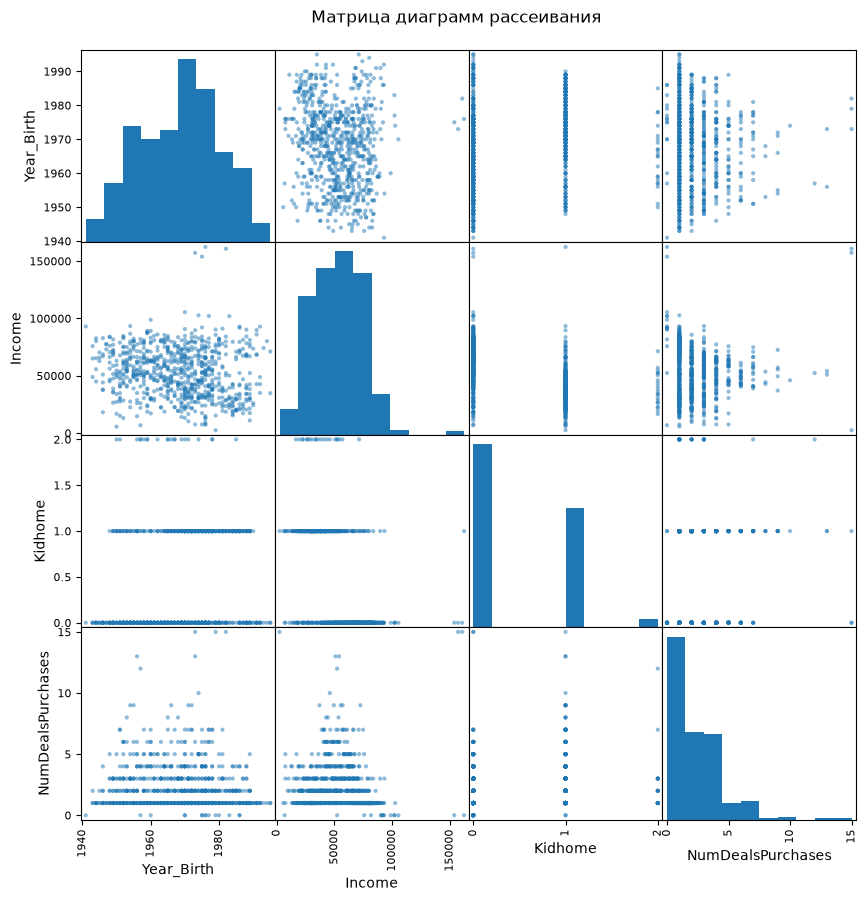

In [20]:
pd.plotting.scatter_matrix(df[numeric_features], figsize=(10, 10))
plt.suptitle('Матрица диаграмм рассеивания', y=0.92)
plt.show()

Матрица диаграмм рассеивания не показывает выраженной линейной зависимости для большинства пар признаков. Наиболее заметна обратная зависимость между `Income` и `Kidhome`: при увеличении количества детей высокий доход встречается реже. Для остальных пар связь визуально слабая.

### 2.2 Диаграмма рассеивания по категориям

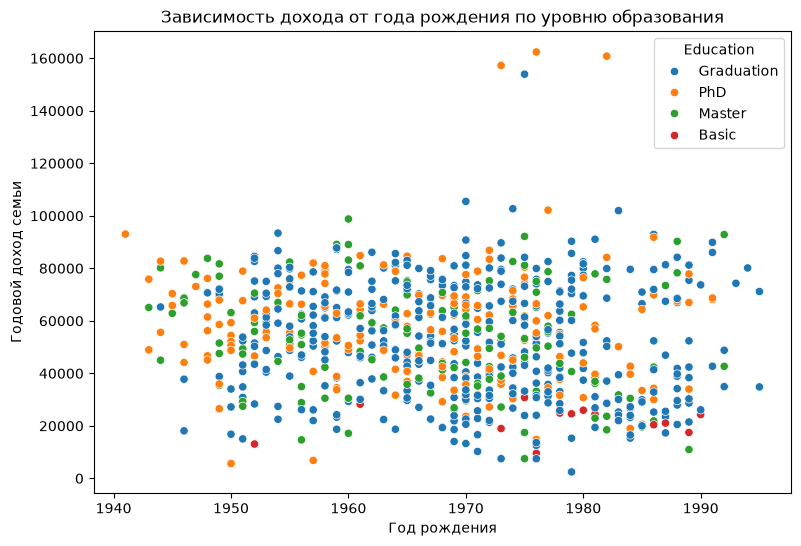

In [21]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Year_Birth', y='Income', hue='Education')
plt.title('Зависимость дохода от года рождения по уровню образования')
plt.xlabel('Год рождения')
plt.ylabel('Годовой доход семьи')
plt.show()

На диаграмме точки разделены по уровню образования. Явной линейной зависимости дохода от года рождения не наблюдается. При этом клиенты с уровнем `Basic` сосредоточены преимущественно в области более низких доходов, а среди клиентов с `PhD`, `Master` и `Graduation` диапазон доходов шире.

## 3. Гистограммы числовых признаков

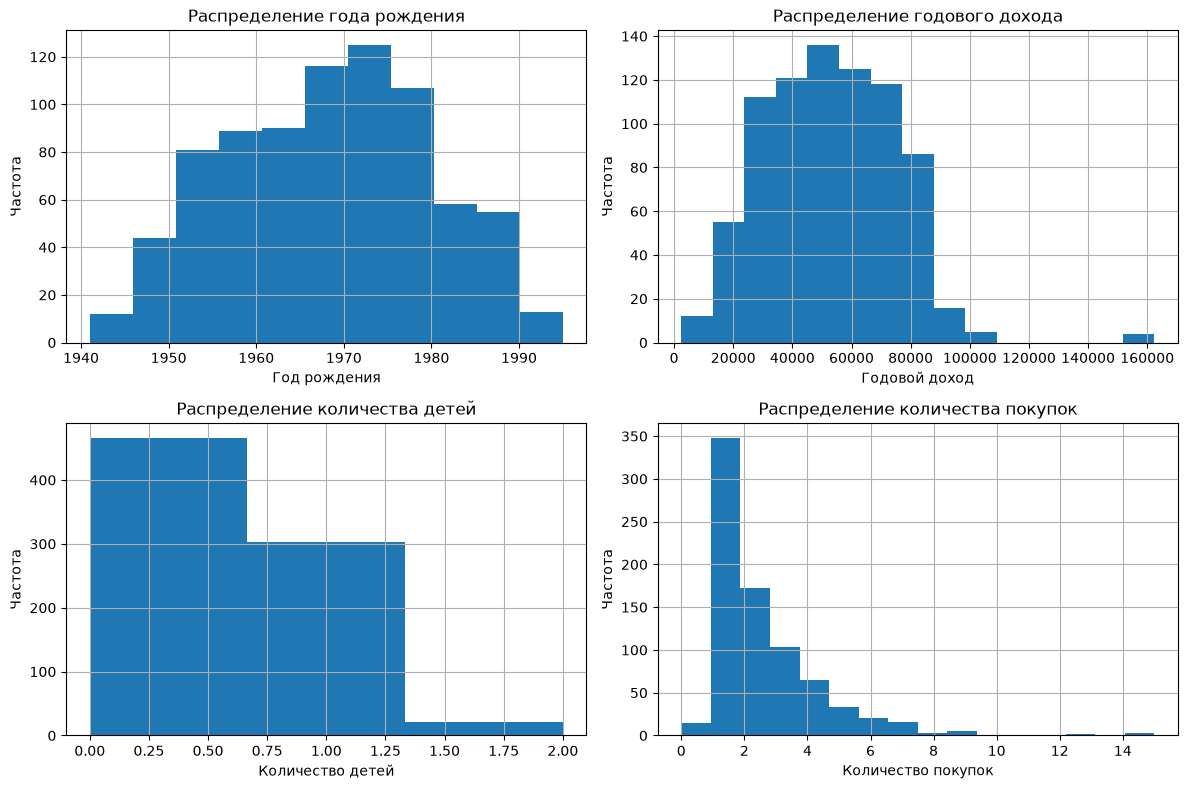

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df['Year_Birth'].hist(bins=11, ax=axes[0, 0])
axes[0, 0].set_title('Распределение года рождения')
axes[0, 0].set_xlabel('Год рождения')
axes[0, 0].set_ylabel('Частота')

df['Income'].hist(bins=15, ax=axes[0, 1])
axes[0, 1].set_title('Распределение годового дохода')
axes[0, 1].set_xlabel('Годовой доход')
axes[0, 1].set_ylabel('Частота')

df['Kidhome'].hist(bins=3, ax=axes[1, 0])
axes[1, 0].set_title('Распределение количества детей')
axes[1, 0].set_xlabel('Количество детей')
axes[1, 0].set_ylabel('Частота')

df['NumDealsPurchases'].hist(bins=16, ax=axes[1, 1])
axes[1, 1].set_title('Распределение количества покупок')
axes[1, 1].set_xlabel('Количество покупок')
axes[1, 1].set_ylabel('Частота')

plt.tight_layout()
plt.show()

Для `Year_Birth` использовано 11 интервалов, что позволяет достаточно подробно показать распределение годов рождения. Для `Income` выбрано 15 интервалов из-за широкого диапазона значений. `Kidhome` принимает только значения 0, 1 и 2, поэтому достаточно 3 интервалов. `NumDealsPurchases` принимает целые значения от 0 до 15, поэтому использовано 16 интервалов.

Большинство клиентов родились в период примерно с конца 1950-х до начала 1980-х годов. Доходы в основном сосредоточены в диапазоне примерно 30000–70000, при этом присутствуют отдельные очень высокие значения. У большинства клиентов нет детей либо имеется один ребёнок. Наиболее часто встречается 1–3 покупки, а большие значения количества покупок встречаются редко.

## 4. Корреляция и ковариация

### 4.1 Матрица корреляции

In [23]:
correlation_matrix = df[numeric_features].corr()
correlation_matrix.round(3)

,Year_Birth,Income,Kidhome,NumDealsPurchases
Year_Birth,1.000,-0.136,0.245,-0.067
Income,-0.136,1.000,-0.528,-0.052
Kidhome,0.245,-0.528,1.000,0.198
NumDealsPurchases,-0.067,-0.052,0.198,1.000


### 4.2 Матрица ковариации

In [24]:
covariance_matrix = df[numeric_features].cov()
covariance_matrix.round(2)

,Year_Birth,Income,Kidhome,NumDealsPurchases
Year_Birth,138.57,-3.466290e+04,1.58,-1.54
Income,-34662.90,4.712551e+08,-6271.46,-2217.00
Kidhome,1.58,-6.271460e+03,0.30,0.21
NumDealsPurchases,-1.54,-2.217000e+03,0.21,3.79


### 4.3 Тепловая карта корреляции

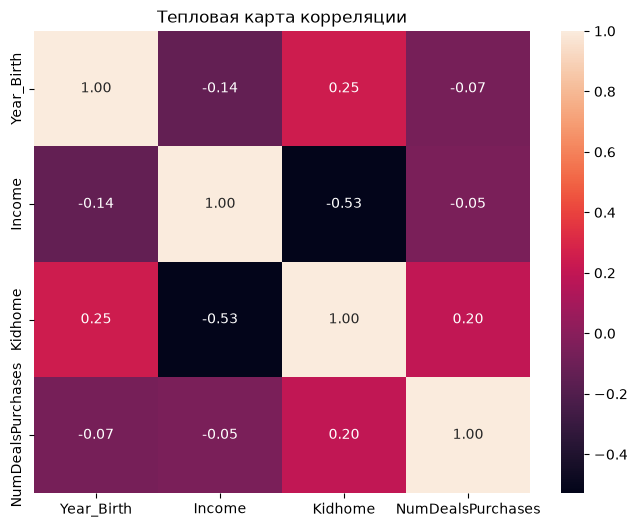

In [25]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f')
plt.title('Тепловая карта корреляции')
plt.show()

Наиболее заметная линейная связь наблюдается между `Income` и `Kidhome`: коэффициент корреляции составляет примерно -0,53, что указывает на умеренную отрицательную связь. Между `Year_Birth` и `Kidhome` наблюдается слабая положительная связь около 0,25, а между `Kidhome` и `NumDealsPurchases` — слабая положительная связь около 0,20. Остальные коэффициенты близки к нулю и не указывают на выраженную линейную связь.

Ковариация подтверждает направления этих связей: отрицательные значения для пар `Income`–`Kidhome` и `Year_Birth`–`Income` соответствуют обратному изменению признаков, а положительная ковариация `Kidhome`–`NumDealsPurchases` — совместному изменению в одном направлении. Абсолютные значения ковариации напрямую сравнивать между разными парами нельзя, так как они зависят от масштаба признаков.

## 5. Графики по варианту 14

### 5.1 Задание 1 — группировка по семейному положению и уровню образования

*Использовать seaborn. По группировке — тип образования и количество клиентов по каждому семейному статусу (`Marital_Status`) построить диаграмму.*

In [26]:
education_status = (
    df.groupby(['Marital_Status', 'Education'])
      .size()
      .reset_index(name='count')
)
education_status

,Marital_Status,Education,count
0,Alone,Graduation,1
1,Alone,Master,1
2,Alone,PhD,1
3,Divorced,Basic,1
4,Divorced,Graduation,49
5,Divorced,Master,12
6,Divorced,PhD,23
7,Married,Basic,9
8,Married,Graduation,170
9,Married,Master,57


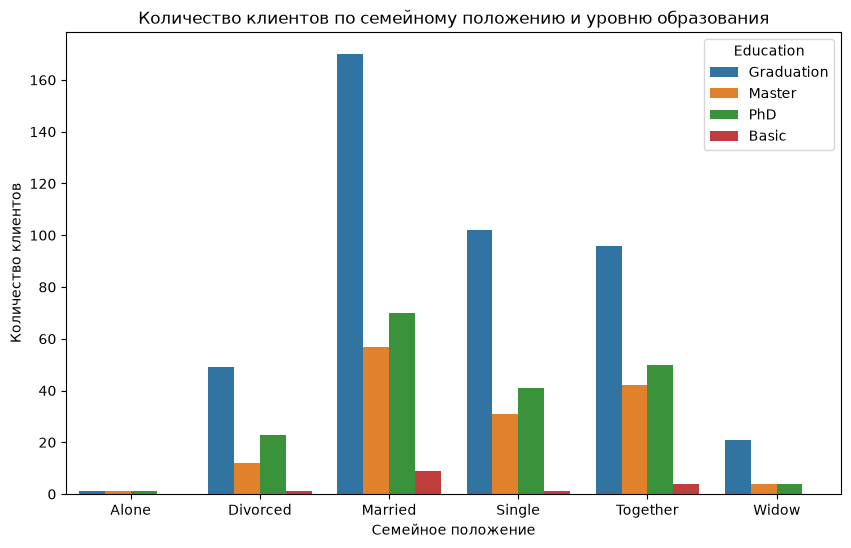

In [27]:
plt.figure(figsize=(10, 6))
sns.barplot(data=education_status, x='Marital_Status', y='count', hue='Education')
plt.title('Количество клиентов по семейному положению и уровню образования')
plt.xlabel('Семейное положение')
plt.ylabel('Количество клиентов')
plt.show()

Во всех наиболее многочисленных семейных статусах преобладают клиенты с уровнем образования `Graduation`. Самая большая группа — `Married` с образованием `Graduation`, она включает 170 клиентов. Среди статусов `Married`, `Single`, `Together` и `Divorced` следующим по численности чаще всего является уровень `PhD` либо `Master`.

### 5.2 Задание 2 — средний доход по семейному положению

*Использовать pandas и plot. По сводной таблице отобразить средний доход семьи по семейному положению. Маркеры — ★, цвет `deeppink`, размер 20.*

In [28]:
income_by_status = df.pivot_table(
    index='Marital_Status',
    values='Income',
    aggfunc='mean'
).round(2)
income_by_status

,Income
Marital_Status,
Alone,43789.00
Divorced,54568.16
Married,52891.47
Single,51105.84
Together,54340.55
Widow,55452.45


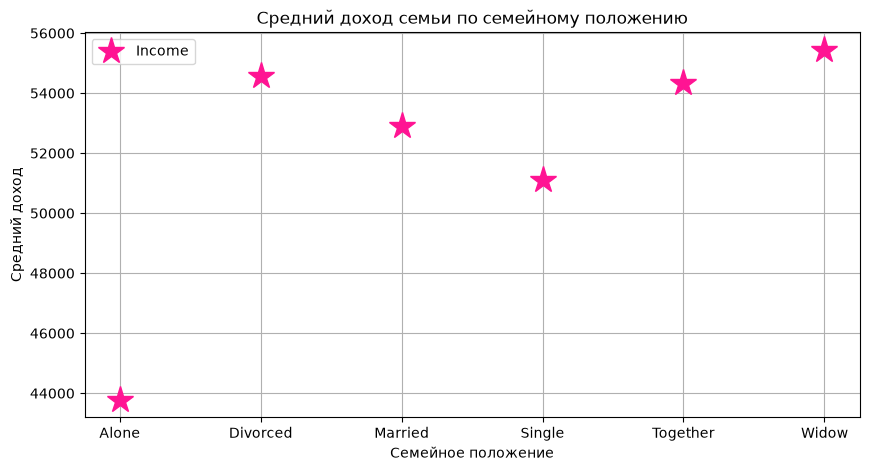

In [29]:
income_by_status.plot(
    marker='*',
    linestyle='None',
    color='deeppink',
    markersize=20,
    figsize=(10, 5)
)
plt.title('Средний доход семьи по семейному положению')
plt.xlabel('Семейное положение')
plt.ylabel('Средний доход')
plt.grid()
plt.show()

Наибольший средний доход наблюдается у клиентов со статусом `Widow` — 55452,45. Наименьшее среднее значение имеет статус `Alone` — 43789,00. Для статусов `Married`, `Single`, `Together` и `Divorced` средний доход находится примерно в диапазоне 51100–54600.

### 5.3 Задание 3 — распределение уровней образования среди клиентов с детьми

*Использовать matplotlib. Отфильтровать клиентов по количеству детей больше 0 и построить круговую диаграмму распределения уровней образования.*

In [30]:
clients_with_children = df[df['Kidhome'] > 0]
education_counts = clients_with_children['Education'].value_counts()
education_counts

Education
Graduation    183
PhD            69
Master         63
Basic           9
Name: count, dtype: int64

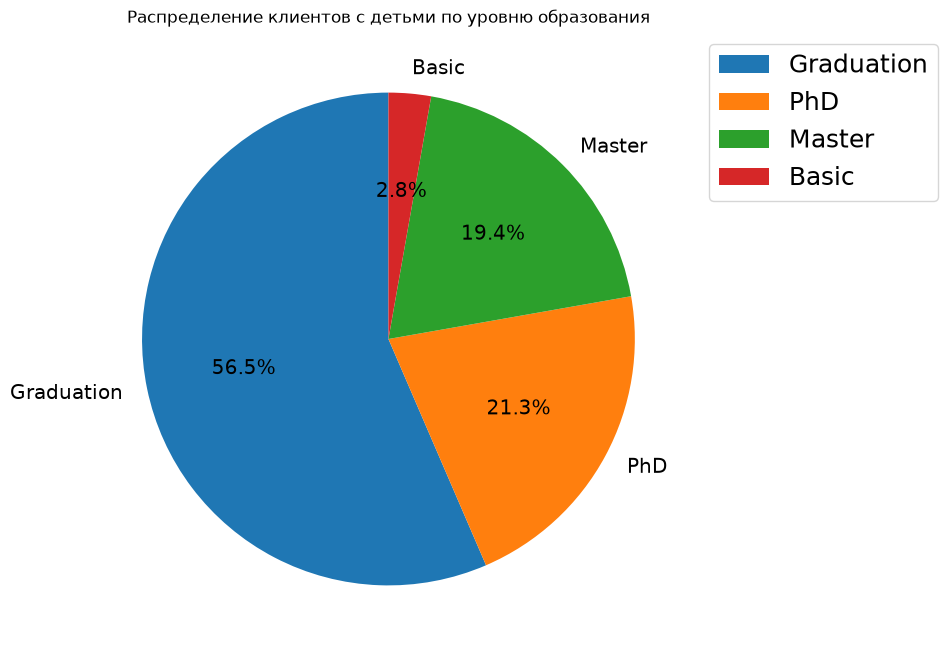

In [31]:
plt.figure(figsize=(10, 8))
plt.pie(
    education_counts.values,
    labels=education_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'size': 'x-large'}
)
plt.title('Распределение клиентов с детьми по уровню образования')
plt.legend(education_counts.index, fontsize=18, bbox_to_anchor=(1, 1))
plt.show()

После фильтрации осталось 324 клиента, имеющих хотя бы одного ребёнка. Наибольшую долю составляют клиенты с образованием `Graduation` — около 56,5%. Далее следуют `PhD` — около 21,3%, `Master` — около 19,4% и `Basic` — около 2,8%.

## 6. Hexagonal binning plot

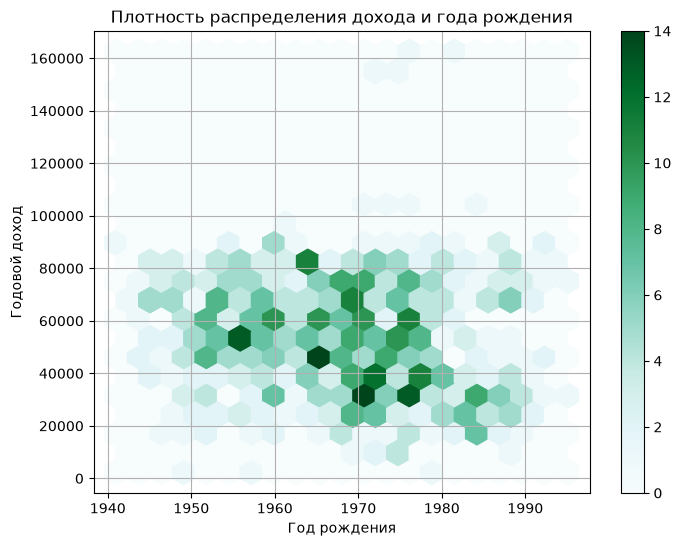

In [32]:
ax = df.plot(
    x='Year_Birth',
    y='Income',
    kind='hexbin',
    gridsize=20,
    figsize=(8, 6),
    sharex=False,
    grid=True
)
ax.set_title('Плотность распределения дохода и года рождения')
ax.set_xlabel('Год рождения')
ax.set_ylabel('Годовой доход')
plt.show()

Наиболее плотные области находятся среди клиентов, родившихся примерно в 1955–1980 годах, с доходом около 30000–70000. Выраженной линейной зависимости между годом рождения и доходом не наблюдается, что согласуется с небольшим коэффициентом корреляции между этими признаками.

## 7. Boxplot для числового столбца

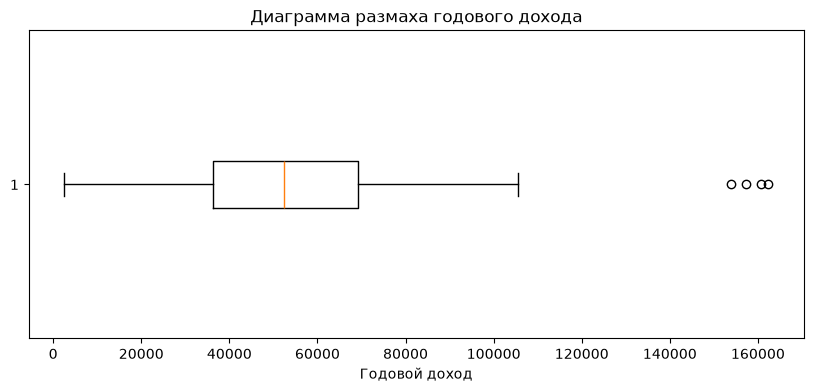

In [33]:
plt.figure(figsize=(10, 4))
plt.boxplot(df['Income'], orientation='horizontal')
plt.title('Диаграмма размаха годового дохода')
plt.xlabel('Годовой доход')
plt.show()

Основная часть значений дохода расположена примерно между 36000 и 69000, медиана составляет около 52000. На диаграмме присутствуют несколько высоких выбросов: значения примерно от 154000 до 162000 заметно отличаются от основной массы данных.

## 8. Категоризация числового признака и boxplot

Для категоризации используется годовой доход `Income`. Выбраны три категории: до 40000 включительно — низкий доход, от 40000 до 70000 включительно — средний, выше 70000 — высокий. Такие границы разделяют диапазон доходов на понятные группы и при этом оставляют достаточное количество наблюдений в каждой категории.

In [34]:
df['Income_Category'] = pd.cut(
    df['Income'],
    bins=[0, 40000, 70000, float('inf')],
    labels=['Низкий', 'Средний', 'Высокий'],
    include_lowest=True
)

df['Income_Category'].value_counts().sort_index()

Income_Category
Низкий     238
Средний    365
Высокий    187
Name: count, dtype: int64

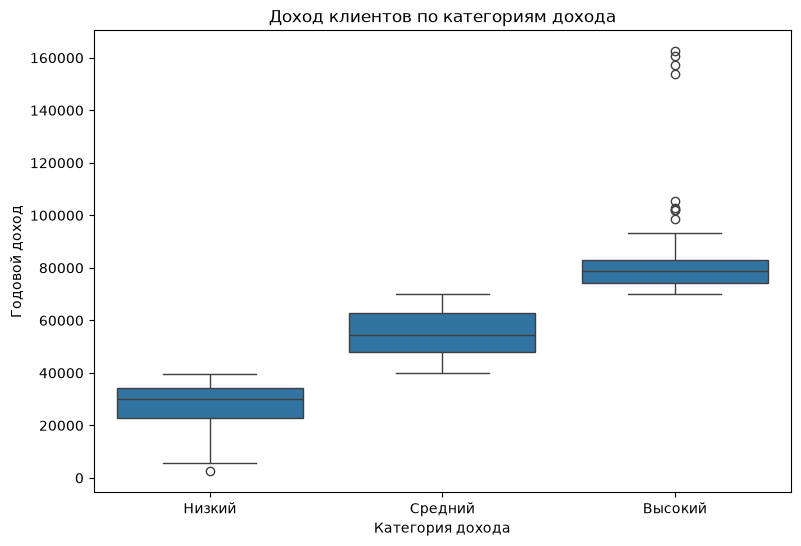

In [35]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='Income_Category', y='Income')
plt.title('Доход клиентов по категориям дохода')
plt.xlabel('Категория дохода')
plt.ylabel('Годовой доход')
plt.show()

В категорию низкого дохода попало 238 клиентов, среднего — 365, высокого — 187. Наибольший разброс наблюдается в категории высокого дохода, где также присутствуют наиболее крупные значения. Категории хорошо разделяют основную часть распределения доходов.

## 9. Дополнительные boxplot по категориям

### 9.1 Доход по уровню образования — seaborn

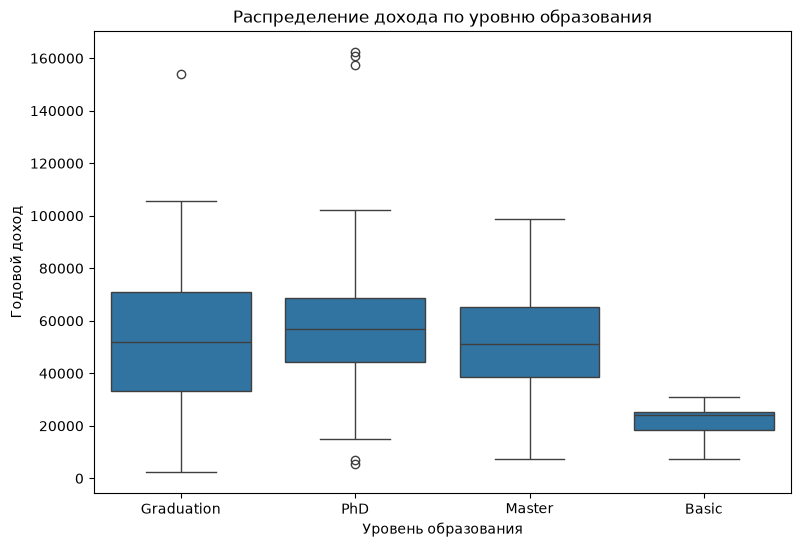

In [36]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='Education', y='Income')
plt.title('Распределение дохода по уровню образования')
plt.xlabel('Уровень образования')
plt.ylabel('Годовой доход')
plt.show()

У клиентов с уровнем `Basic` доходы заметно ниже, чем в остальных группах. Среди основных категорий наиболее высокая медиана дохода наблюдается у клиентов с `PhD`. В группах `Graduation` и `PhD` также заметны отдельные высокие значения дохода.

### 9.2 Количество покупок по семейному положению — pandas

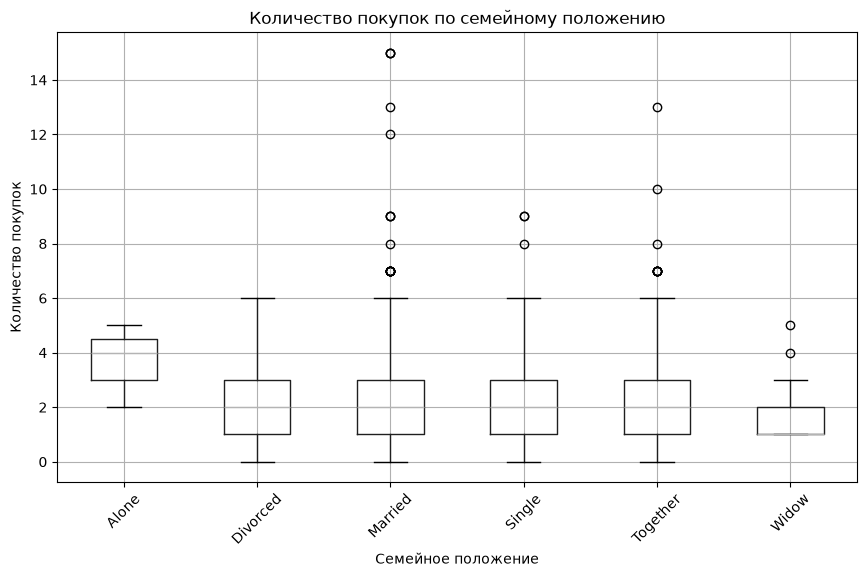

In [37]:
df.boxplot(
    column='NumDealsPurchases',
    by='Marital_Status',
    figsize=(10, 6)
)
plt.suptitle('')
plt.title('Количество покупок по семейному положению')
plt.xlabel('Семейное положение')
plt.ylabel('Количество покупок')
plt.xticks(rotation=45)
plt.show()

Для большинства семейных статусов медианное количество покупок составляет около 2. У клиентов со статусами `Married` и `Together` присутствуют наиболее высокие отдельные значения количества покупок. Для категории `Alone` наблюдений всего три, поэтому её распределение следует интерпретировать осторожно.

## 10. Вывод

В ходе лабораторной работы был выполнен исследовательский анализ набора данных `clients.csv`, содержащего сведения о клиентах магазина. Исходный набор включал 796 записей и 8 столбцов. После обработки пропусков, удаления 4 явных дубликатов, устранения неявных дубликатов в семейном положении, преобразования типов данных и удаления аномального значения года рождения в наборе осталось 790 записей.

Для количественных признаков были построены матрица диаграмм рассеивания и гистограммы. Распределение дохода сосредоточено преимущественно в диапазоне 30000–70000, большинство клиентов имеют 0 или 1 ребёнка, а наиболее часто встречается небольшое количество покупок.

Корреляционный анализ показал, что наиболее заметная линейная связь наблюдается между годовым доходом и количеством детей: коэффициент корреляции составляет около -0,53, то есть связь является умеренной отрицательной. Остальные зависимости значительно слабее. Это также подтверждается диаграммами рассеивания и тепловой картой.

По заданию варианта установлено, что наиболее многочисленная группа — клиенты с семейным статусом `Married` и образованием `Graduation` (170 человек). Наибольший средний доход наблюдается у клиентов со статусом `Widow` — 55452,45, а наименьший — у `Alone` — 43789,00. Среди клиентов, имеющих детей, около 56,5% имеют образование `Graduation`.

Дополнительно были построены hexagonal binning plot и несколько диаграмм размаха. Boxplot дохода показал наличие нескольких очень высоких значений, а сравнение по уровню образования показало более низкий уровень дохода у группы `Basic`. В целом визуализация и числовые показатели позволили выявить основные особенности распределений и взаимосвязей в наборе данных.